1. Understand the workflow
Suppose you are building a simple order-processing system.
- If the order amount is ₹500 or more → approve the order.
- If the order amount is less than ₹500 → send it for review.

In [23]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [24]:
class OrderState(TypedDict):
    amount: int
    state: str

In [25]:
# 2. Node: Approve the order
def approve_order(state: OrderState):
    print("Order approve!")
    return {'status': "approve"}

In [26]:
# 3 Node: send the order for review
def review_order(state: OrderState):
    print("Order sent for review.")
    return {'status': "Under Review"}

In [27]:
# 4 Conditional function: Choose the next node
def check_amount(state: OrderState):
    if state['amount'] >= 500:
        return 'approve'
    return 'review'

In [28]:
graph = StateGraph(OrderState)

graph.add_node('approve',approve_order)
graph.add_node('review',review_order)

graph.add_conditional_edges(
    START,
    check_amount,
    {
        'approve': 'approve',
        'review':'review'
    }
)
# Both paths finish the workflow
graph.add_edge('approve', END)
graph.add_edge('review', END)

workflow = graph.compile()

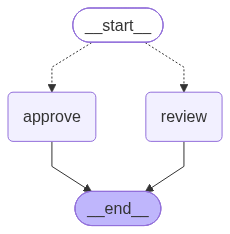

In [29]:
workflow

In [32]:
# 6. Run the workflow
result = workflow.invoke({
    "amount": 500,
    "status": ""
})

print(result)


Order approve!
{'amount': 500}
